In [1]:
from pathlib import Path
import os
import sys
import numpy as np
import pandas as pd
import scipy
import wfdb

PROJECT_ROOT = Path.cwd().parent
MIMIC_ROOT = Path(os.environ["MIMIC_WAVEFORM_ROOT"])

print("Python:", sys.version.split()[0])
print("Proyecto:", PROJECT_ROOT)
print("Dataset encontrado:", MIMIC_ROOT.exists())
print("Ruta del dataset:", MIMIC_ROOT)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("SciPy:", scipy.__version__)
print("WFDB:", wfdb.__version__)

In [2]:
# Verificación mínima de un encabezado WFDB con señal ABP.
# No cuenta pacientes, registros ni segmentos.
# No carga todavía la forma de onda completa.

waves_dir = MIMIC_ROOT / "waves"

if not waves_dir.exists():
    raise FileNotFoundError(f"No se encontró la carpeta de señales: {waves_dir}")

abp_header = None
abp_aliases = {"ABP", "ART", "ARTERIAL", "AO"}

for header_path in waves_dir.rglob("*.hea"):
    try:
        header_text = header_path.read_text(
            encoding="utf-8",
            errors="ignore"
        ).upper()

        if any(alias in header_text for alias in abp_aliases):
            abp_header = header_path
            break
    except OSError:
        continue

if abp_header is None:
    raise RuntimeError(
        "No se encontró ningún encabezado candidato con señal ABP."
    )

record_base = abp_header.with_suffix("")
record_header = wfdb.rdheader(str(record_base))

signal_names = [str(name) for name in record_header.sig_name]
signal_units = [
    str(unit) if unit is not None else "desconocida"
    for unit in record_header.units
]

abp_channels = [
    index
    for index, name in enumerate(signal_names)
    if name.strip().upper() in abp_aliases
]

duration_seconds = (
    record_header.sig_len / record_header.fs
    if record_header.fs and record_header.sig_len
    else np.nan
)

print("Encabezado ABP localizado: Sí")
print("Identificador mostrado: No, protegido")
print("Frecuencia de muestreo:", record_header.fs, "Hz")
print("Número de muestras:", record_header.sig_len)
print("Duración:", round(duration_seconds, 2), "segundos")
print("Número de canales:", record_header.n_sig)
print("Señales disponibles:", signal_names)
print("Unidades:", signal_units)
print("Índices candidatos ABP:", abp_channels)

Encabezado ABP localizado: Sí
Identificador mostrado: No, protegido
Frecuencia de muestreo: 62.4725 Hz
Número de muestras: 0
Duración: nan segundos
Número de canales: 7
Señales disponibles: ['II', 'III', 'V', 'aVR', 'ABP', 'Pleth', 'Resp']
Unidades: ['mV', 'mV', 'mV', 'mV', 'mmHg', 'NU', 'Ohm']
Índices candidatos ABP: [4]


In [3]:
# Localizar un segmento WFDB real con ABP y cargar solo el primer minuto.
# No muestra identificadores ni repite el inventario de la base.

abp_segment_header = None
abp_segment_info = None

for header_path in waves_dir.rglob("*.hea"):
    try:
        candidate_base = header_path.with_suffix("")
        candidate_header = wfdb.rdheader(str(candidate_base))

        names = [str(name).strip() for name in candidate_header.sig_name]
        upper_names = [name.upper() for name in names]

        candidate_channels = [
            index
            for index, name in enumerate(upper_names)
            if name in abp_aliases
        ]

        if (
            candidate_channels
            and candidate_header.sig_len is not None
            and candidate_header.sig_len > 0
            and candidate_header.fs is not None
            and candidate_header.fs > 0
        ):
            abp_segment_header = header_path
            abp_segment_info = candidate_header
            break

    except (OSError, ValueError, TypeError):
        continue

if abp_segment_header is None:
    raise RuntimeError(
        "No se encontró un segmento físico con ABP y muestras disponibles."
    )

segment_base = abp_segment_header.with_suffix("")

segment_names = [
    str(name).strip()
    for name in abp_segment_info.sig_name
]

segment_units = [
    str(unit) if unit is not None else "desconocida"
    for unit in abp_segment_info.units
]

segment_abp_channels = [
    index
    for index, name in enumerate(segment_names)
    if name.upper() in abp_aliases
]

abp_index = segment_abp_channels[0]
fs = float(abp_segment_info.fs)
total_samples = int(abp_segment_info.sig_len)
samples_to_read = min(total_samples, int(round(60 * fs)))

record = wfdb.rdrecord(
    str(segment_base),
    sampfrom=0,
    sampto=samples_to_read,
    channels=[abp_index],
    physical=True,
)

abp = np.asarray(record.p_signal[:, 0], dtype=float)
finite_abp = abp[np.isfinite(abp)]

duration_loaded = len(abp) / fs

print("Segmento físico localizado: Sí")
print("Identificador mostrado: No, protegido")
print("Canal cargado:", segment_names[abp_index])
print("Unidad:", segment_units[abp_index])
print("Frecuencia de muestreo:", fs, "Hz")
print("Muestras totales del segmento:", total_samples)
print("Muestras cargadas:", len(abp))
print("Duración cargada:", round(duration_loaded, 2), "segundos")
print("Valores finitos:", len(finite_abp))
print("Valores faltantes:", int(np.isnan(abp).sum()))

if len(finite_abp) > 0:
    print("Presión mínima:", round(float(np.min(finite_abp)), 2), "mmHg")
    print("Presión mediana:", round(float(np.median(finite_abp)), 2), "mmHg")
    print("Presión máxima:", round(float(np.max(finite_abp)), 2), "mmHg")
else:
    print("Advertencia: el intervalo cargado no contiene valores ABP finitos.")

Segmento físico localizado: Sí
Identificador mostrado: No, protegido
Canal cargado: ABP
Unidad: mmHg
Frecuencia de muestreo: 62.4725 Hz
Muestras totales del segmento: 196480
Muestras cargadas: 3748
Duración cargada: 59.99 segundos
Valores finitos: 3492
Valores faltantes: 256
Presión mínima: 25.0 mmHg
Presión mediana: 28.81 mmHg
Presión máxima: 32.0 mmHg


Resumen de calidad del minuto
-----------------------------
Porcentaje faltante: 6.83 %
Media: 28.87 mmHg
Desviación estándar: 0.46 mmHg
Rango total: 7.0 mmHg
Percentiles 1, 5, 25, 50, 75, 95 y 99:
[28.19 28.38 28.56 28.81 29.06 29.75 30.12]


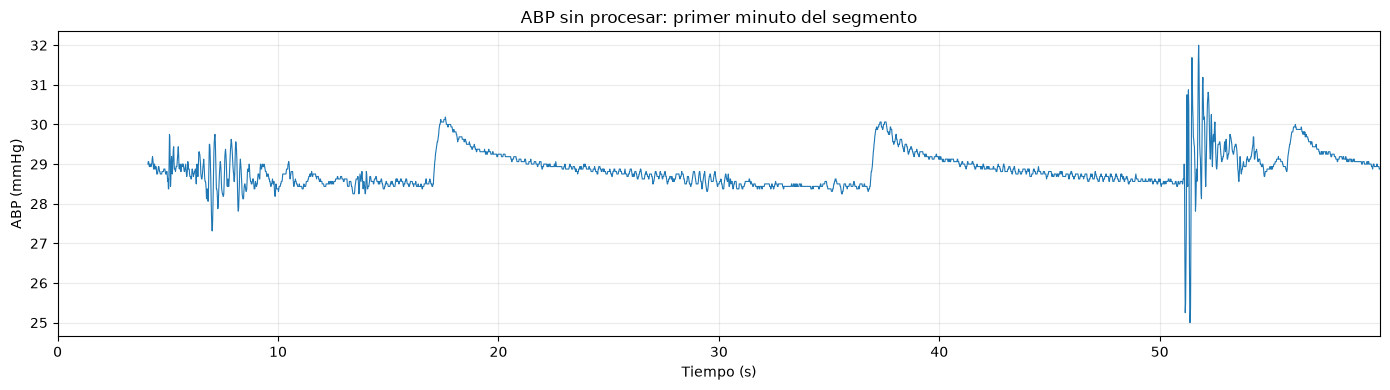

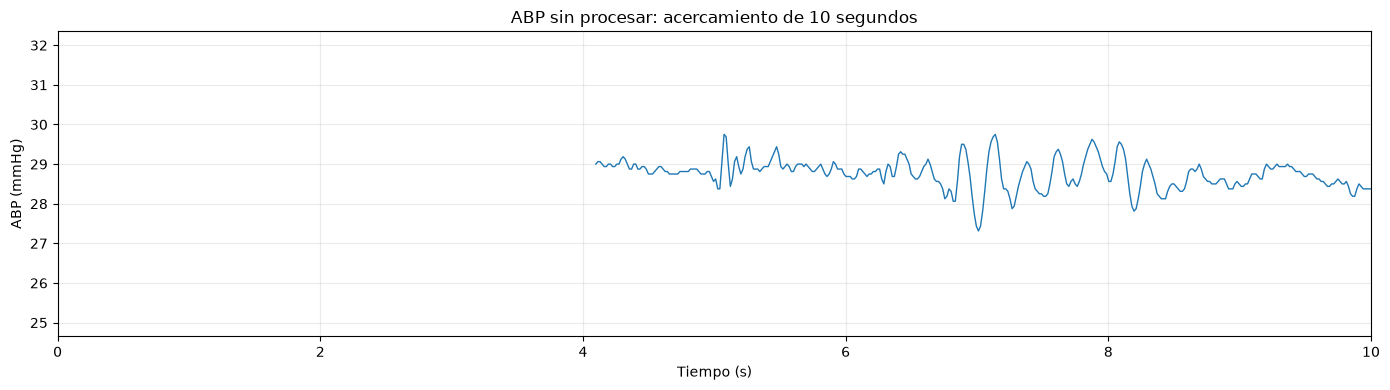

In [4]:
import matplotlib.pyplot as plt

time_seconds = np.arange(len(abp)) / fs
missing_fraction = np.mean(~np.isfinite(abp))

if len(finite_abp) == 0:
    raise RuntimeError("El intervalo no contiene valores ABP finitos.")

percentiles = np.percentile(
    finite_abp,
    [1, 5, 25, 50, 75, 95, 99]
)

print("Resumen de calidad del minuto")
print("-----------------------------")
print("Porcentaje faltante:", round(100 * missing_fraction, 2), "%")
print("Media:", round(float(np.mean(finite_abp)), 2), "mmHg")
print("Desviación estándar:", round(float(np.std(finite_abp)), 2), "mmHg")
print("Rango total:", round(float(np.ptp(finite_abp)), 2), "mmHg")
print("Percentiles 1, 5, 25, 50, 75, 95 y 99:")
print(np.round(percentiles, 2))

plt.figure(figsize=(14, 4))
plt.plot(time_seconds, abp, linewidth=0.8)
plt.xlabel("Tiempo (s)")
plt.ylabel("ABP (mmHg)")
plt.title("ABP sin procesar: primer minuto del segmento")
plt.xlim(0, duration_loaded)
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# Acercamiento de los primeros 10 segundos con datos.
plt.figure(figsize=(14, 4))
plt.plot(time_seconds, abp, linewidth=1.0)
plt.xlabel("Tiempo (s)")
plt.ylabel("ABP (mmHg)")
plt.title("ABP sin procesar: acercamiento de 10 segundos")
plt.xlim(0, min(10, duration_loaded))
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [5]:
# Cargar el canal ABP completo del segmento y buscar ventanas candidatas.
# La selección es preliminar y sirve para inspección, no constituye todavía
# el algoritmo definitivo de control de calidad.

full_record = wfdb.rdrecord(
    str(segment_base),
    sampfrom=0,
    sampto=total_samples,
    channels=[abp_index],
    physical=True,
)

abp_full = np.asarray(full_record.p_signal[:, 0], dtype=float)

window_seconds = 30
step_seconds = 15

window_samples = int(round(window_seconds * fs))
step_samples = int(round(step_seconds * fs))

window_results = []

for start in range(
    0,
    len(abp_full) - window_samples + 1,
    step_samples
):
    stop = start + window_samples
    window = abp_full[start:stop]
    finite = window[np.isfinite(window)]

    finite_fraction = len(finite) / len(window)

    if len(finite) < 10:
        continue

    p01, p05, p50, p95, p99 = np.percentile(
        finite,
        [1, 5, 50, 95, 99]
    )

    robust_amplitude = p95 - p05
    extreme_amplitude = p99 - p01

    # Criterios preliminares para localizar candidatos visuales.
    candidate = (
        finite_fraction >= 0.99
        and 40 <= p50 <= 160
        and 15 <= robust_amplitude <= 120
        and 20 <= p01
        and p99 <= 250
    )

    window_results.append(
        {
            "start_sample": start,
            "start_seconds": start / fs,
            "finite_percent": 100 * finite_fraction,
            "median_mmhg": p50,
            "robust_amplitude_mmhg": robust_amplitude,
            "extreme_amplitude_mmhg": extreme_amplitude,
            "candidate": candidate,
        }
    )

window_table = pd.DataFrame(window_results)

candidates = (
    window_table[window_table["candidate"]]
    .sort_values(
        ["finite_percent", "robust_amplitude_mmhg"],
        ascending=[False, False],
    )
    .reset_index(drop=True)
)

print("Duración total del segmento:",
      round(len(abp_full) / fs / 60, 2), "minutos")
print("Ventanas evaluadas:", len(window_table))
print("Ventanas candidatas preliminares:", len(candidates))

if len(candidates) == 0:
    print(
        "No se encontró una ventana que cumpla los criterios "
        "preliminares en este segmento."
    )
else:
    display(
        candidates[
            [
                "start_seconds",
                "finite_percent",
                "median_mmhg",
                "robust_amplitude_mmhg",
                "extreme_amplitude_mmhg",
            ]
        ].head(10).round(2)
    )

    best_start = int(candidates.loc[0, "start_sample"])
    best_stop = best_start + window_samples

    best_abp = abp_full[best_start:best_stop]
    best_time = np.arange(len(best_abp)) / fs

    plt.figure(figsize=(14, 4))
    plt.plot(best_time, best_abp, linewidth=0.8)
    plt.xlabel("Tiempo dentro de la ventana (s)")
    plt.ylabel("ABP (mmHg)")
    plt.title(
        "Mejor ventana candidata de ABP dentro del segmento"
    )
    plt.xlim(0, window_seconds)
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(14, 4))
    plt.plot(best_time, best_abp, linewidth=1.0)
    plt.xlabel("Tiempo dentro de la ventana (s)")
    plt.ylabel("ABP (mmHg)")
    plt.title(
        "Acercamiento de la ventana candidata: primeros 10 segundos"
    )
    plt.xlim(0, 10)
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

Duración total del segmento: 52.42 minutos
Ventanas evaluadas: 208
Ventanas candidatas preliminares: 0
No se encontró una ventana que cumpla los criterios preliminares en este segmento.


Segmentos ABP revisados: 5
Ventanas candidatas encontradas: 7


,Candidato,Frecuencia_Hz,Datos_finitos_%,Mediana_mmHg,P05_mmHg,P95_mmHg,Amplitud_robusta_mmHg,IQR_mmHg
0,1,62.47,100.0,86.66,75.44,114.77,39.33,15.05
1,2,62.47,100.0,74.81,67.38,94.83,27.46,9.31
2,3,62.47,100.0,69.78,58.27,95.40,37.13,11.80
3,4,62.47,100.0,76.28,63.10,102.76,39.66,13.48
4,5,62.47,100.0,70.75,61.88,94.00,32.12,11.09
5,6,62.47,100.0,78.62,67.94,106.83,38.90,15.62
6,7,62.47,100.0,71.38,62.38,95.88,33.50,11.81


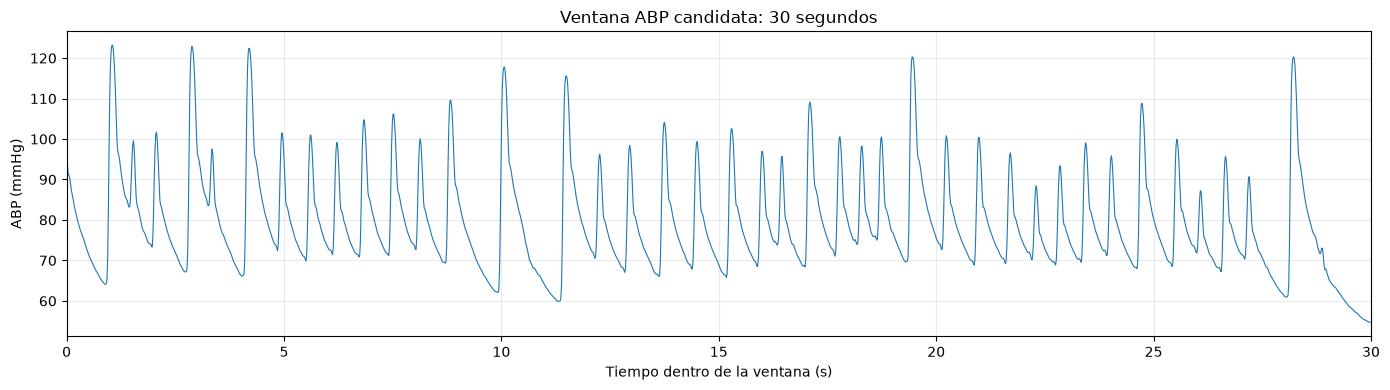

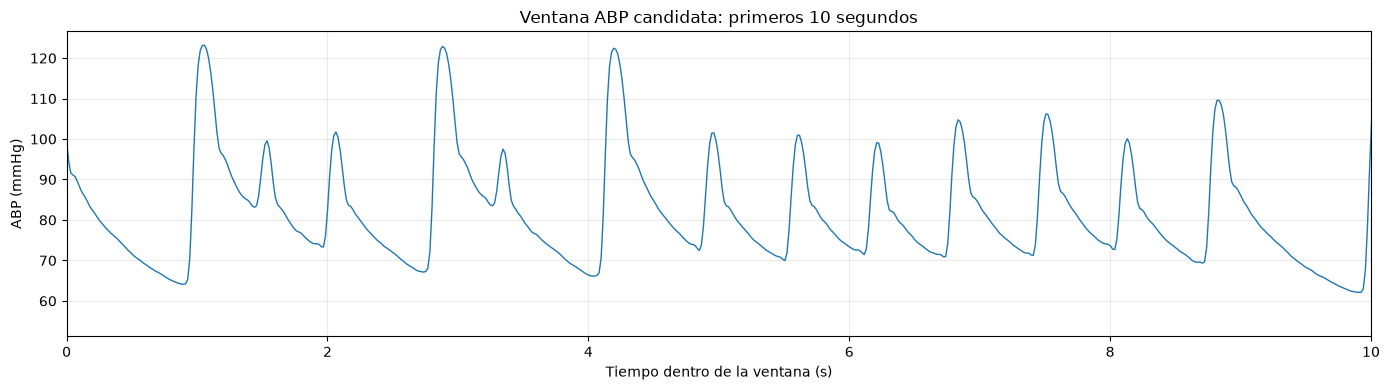

In [6]:
# Búsqueda dirigida de ventanas ABP utilizables en otros segmentos.
# No cuenta nuevamente pacientes ni registros y no muestra identificadores.

candidate_windows = []
segments_checked = 0
maximum_segments = 100

window_seconds = 30
relative_positions = [0.05, 0.25, 0.50, 0.75]

for header_path in waves_dir.rglob("*.hea"):
    if segments_checked >= maximum_segments:
        break

    try:
        candidate_base = header_path.with_suffix("")
        header = wfdb.rdheader(str(candidate_base))

        names = [
            str(name).strip()
            for name in header.sig_name
        ]

        abp_indices = [
            index
            for index, name in enumerate(names)
            if name.upper() in abp_aliases
        ]

        if (
            not abp_indices
            or header.sig_len is None
            or header.sig_len <= 0
            or header.fs is None
            or header.fs <= 0
        ):
            continue

        segments_checked += 1

        candidate_fs = float(header.fs)
        candidate_total = int(header.sig_len)
        candidate_abp_index = abp_indices[0]
        candidate_window_samples = int(
            round(window_seconds * candidate_fs)
        )

        if candidate_total < candidate_window_samples:
            continue

        for relative_position in relative_positions:
            start = int(
                relative_position
                * max(
                    candidate_total - candidate_window_samples,
                    0,
                )
            )
            stop = start + candidate_window_samples

            try:
                candidate_record = wfdb.rdrecord(
                    str(candidate_base),
                    sampfrom=start,
                    sampto=stop,
                    channels=[candidate_abp_index],
                    physical=True,
                )
            except Exception:
                continue

            signal = np.asarray(
                candidate_record.p_signal[:, 0],
                dtype=float,
            )

            finite = signal[np.isfinite(signal)]
            finite_fraction = len(finite) / len(signal)

            if len(finite) < 100:
                continue

            p01, p05, p25, p50, p75, p95, p99 = (
                np.percentile(
                    finite,
                    [1, 5, 25, 50, 75, 95, 99],
                )
            )

            robust_amplitude = p95 - p05
            interquartile_range = p75 - p25

            plausible = (
                finite_fraction >= 0.99
                and 35 <= p50 <= 180
                and 10 <= robust_amplitude <= 120
                and interquartile_range >= 3
                and p01 >= 15
                and p99 <= 250
            )

            if plausible:
                candidate_windows.append(
                    {
                        "header_path": header_path,
                        "record_base": candidate_base,
                        "channel_index": candidate_abp_index,
                        "channel_name": names[candidate_abp_index],
                        "fs": candidate_fs,
                        "start_sample": start,
                        "signal": signal,
                        "finite_percent": 100 * finite_fraction,
                        "median_mmhg": p50,
                        "p05_mmhg": p05,
                        "p95_mmhg": p95,
                        "robust_amplitude_mmhg": robust_amplitude,
                        "iqr_mmhg": interquartile_range,
                    }
                )

        if len(candidate_windows) >= 5:
            break

    except Exception:
        continue

print("Segmentos ABP revisados:", segments_checked)
print("Ventanas candidatas encontradas:", len(candidate_windows))

if not candidate_windows:
    print(
        "No se encontraron ventanas plausibles en esta búsqueda. "
        "Será necesario revisar los criterios o ampliar la búsqueda."
    )
else:
    candidate_summary = pd.DataFrame(
        [
            {
                "Candidato": index + 1,
                "Frecuencia_Hz": item["fs"],
                "Datos_finitos_%": item["finite_percent"],
                "Mediana_mmHg": item["median_mmhg"],
                "P05_mmHg": item["p05_mmhg"],
                "P95_mmHg": item["p95_mmhg"],
                "Amplitud_robusta_mmHg":
                    item["robust_amplitude_mmhg"],
                "IQR_mmHg": item["iqr_mmhg"],
            }
            for index, item in enumerate(candidate_windows)
        ]
    )

    display(candidate_summary.round(2))

    # Selección preliminar del candidato con mayor amplitud robusta.
    best_candidate = max(
        candidate_windows,
        key=lambda item: item["robust_amplitude_mmhg"],
    )

    best_abp = best_candidate["signal"]
    best_fs = best_candidate["fs"]
    best_time = np.arange(len(best_abp)) / best_fs

    plt.figure(figsize=(14, 4))
    plt.plot(best_time, best_abp, linewidth=0.8)
    plt.xlabel("Tiempo dentro de la ventana (s)")
    plt.ylabel("ABP (mmHg)")
    plt.title("Ventana ABP candidata: 30 segundos")
    plt.xlim(0, window_seconds)
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(14, 4))
    plt.plot(best_time, best_abp, linewidth=1.0)
    plt.xlabel("Tiempo dentro de la ventana (s)")
    plt.ylabel("ABP (mmHg)")
    plt.title("Ventana ABP candidata: primeros 10 segundos")
    plt.xlim(0, 10)
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

Picos sistólicos detectados: 40
Frecuencia cardiaca mediana: 87.2 lpm
Rango de frecuencia instantánea: 41.6 - 133.9 lpm
Intervalo entre pulsos mediano: 0.688 s
Presión sistólica mediana detectada: 100.47 mmHg


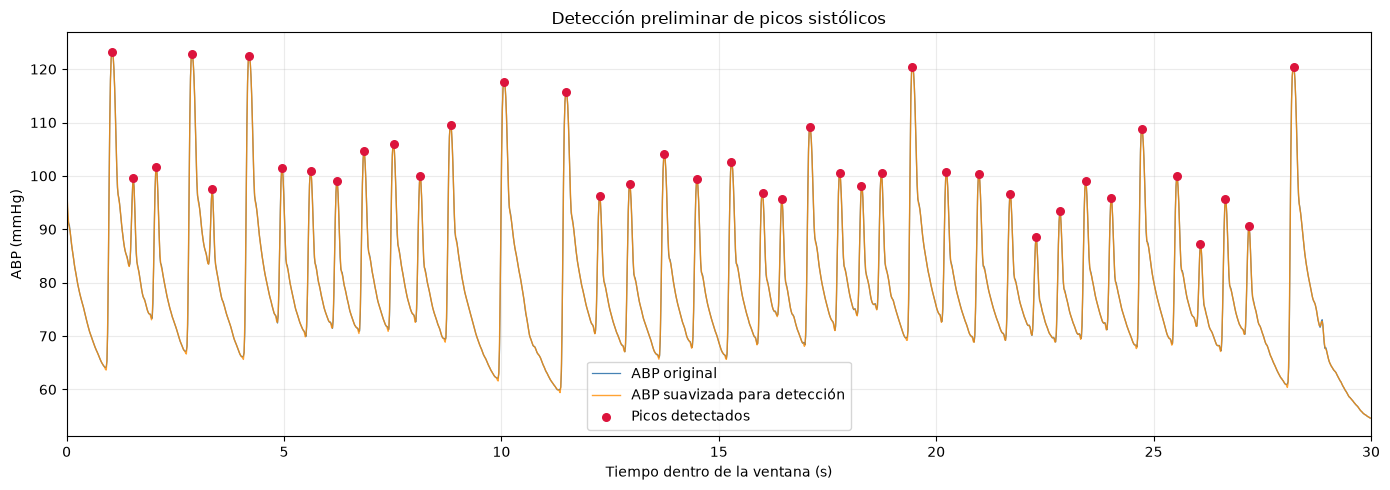

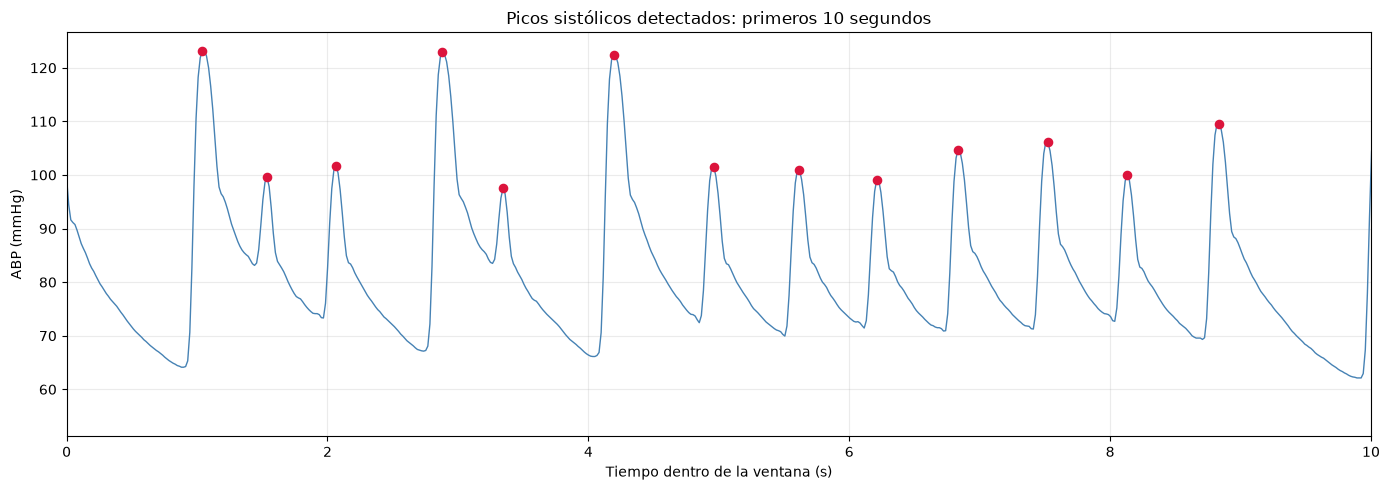

In [7]:
from scipy.signal import find_peaks, savgol_filter

# Trabajar con la ventana candidata seleccionada anteriormente.
signal = np.asarray(best_abp, dtype=float)
time = np.arange(len(signal)) / best_fs

if not np.isfinite(signal).all():
    raise ValueError(
        "La ventana contiene datos faltantes; no se realizará detección."
    )

# Suavizado ligero únicamente para localizar máximos.
smooth_samples = max(5, int(round(0.11 * best_fs)))
if smooth_samples % 2 == 0:
    smooth_samples += 1

abp_smooth = savgol_filter(
    signal,
    window_length=smooth_samples,
    polyorder=2,
)

# Restricción preliminar: no más de 180 pulsos por minuto.
minimum_peak_distance = int(round(0.33 * best_fs))

robust_amplitude = (
    np.percentile(signal, 95)
    - np.percentile(signal, 5)
)

minimum_prominence = max(
    5.0,
    0.15 * robust_amplitude,
)

systolic_peaks, peak_properties = find_peaks(
    abp_smooth,
    distance=minimum_peak_distance,
    prominence=minimum_prominence,
)

peak_times = time[systolic_peaks]
systolic_pressures = signal[systolic_peaks]

if len(systolic_peaks) >= 2:
    beat_intervals = np.diff(peak_times)
    instantaneous_hr = 60.0 / beat_intervals

    print("Picos sistólicos detectados:", len(systolic_peaks))
    print(
        "Frecuencia cardiaca mediana:",
        round(float(np.median(instantaneous_hr)), 1),
        "lpm",
    )
    print(
        "Rango de frecuencia instantánea:",
        round(float(np.min(instantaneous_hr)), 1),
        "-",
        round(float(np.max(instantaneous_hr)), 1),
        "lpm",
    )
    print(
        "Intervalo entre pulsos mediano:",
        round(float(np.median(beat_intervals)), 3),
        "s",
    )
    print(
        "Presión sistólica mediana detectada:",
        round(float(np.median(systolic_pressures)), 2),
        "mmHg",
    )
else:
    print(
        "No se detectaron suficientes pulsos para caracterizar la ventana."
    )

plt.figure(figsize=(14, 5))
plt.plot(
    time,
    signal,
    color="steelblue",
    linewidth=0.9,
    label="ABP original",
)
plt.plot(
    time,
    abp_smooth,
    color="darkorange",
    linewidth=1.0,
    alpha=0.8,
    label="ABP suavizada para detección",
)
plt.scatter(
    peak_times,
    systolic_pressures,
    color="crimson",
    s=30,
    zorder=3,
    label="Picos detectados",
)

plt.xlabel("Tiempo dentro de la ventana (s)")
plt.ylabel("ABP (mmHg)")
plt.title("Detección preliminar de picos sistólicos")
plt.xlim(0, 30)
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(14, 5))
plt.plot(
    time,
    signal,
    color="steelblue",
    linewidth=1.0,
)
plt.scatter(
    peak_times,
    systolic_pressures,
    color="crimson",
    s=35,
    zorder=3,
)

plt.xlabel("Tiempo dentro de la ventana (s)")
plt.ylabel("ABP (mmHg)")
plt.title("Picos sistólicos detectados: primeros 10 segundos")
plt.xlim(0, 10)
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

Intervalos entre pulsos analizados: 39
Pulsos plausibles preliminares: 39
Pulsos excluidos preliminarmente: 0


,beat,duration_s,heart_rate_bpm,systolic_mmhg,diastolic_mmhg,pulse_pressure_mmhg,plausible
0,1,0.50,120.91,123.12,83.12,40.00,True
1,2,0.53,113.59,99.56,73.31,26.25,True
2,3,0.82,73.50,101.75,67.12,34.62,True
3,4,0.46,129.25,122.88,83.50,39.38,True
4,5,0.85,70.72,97.50,66.12,31.38,True
5,6,0.77,78.09,122.44,72.44,50.00,True
6,7,0.66,91.42,101.50,69.94,31.56,True
7,8,0.59,101.31,100.94,71.44,29.50,True
8,9,0.62,96.11,99.12,70.88,28.25,True
9,10,0.69,87.17,104.75,71.25,33.50,True



Resumen de pulsos
-----------------
Duración mediana: 0.688 s
Sistólica mediana: 100.44 mmHg
Diastólica mediana: 69.62 mmHg
Presión de pulso mediana: 31.25 mmHg


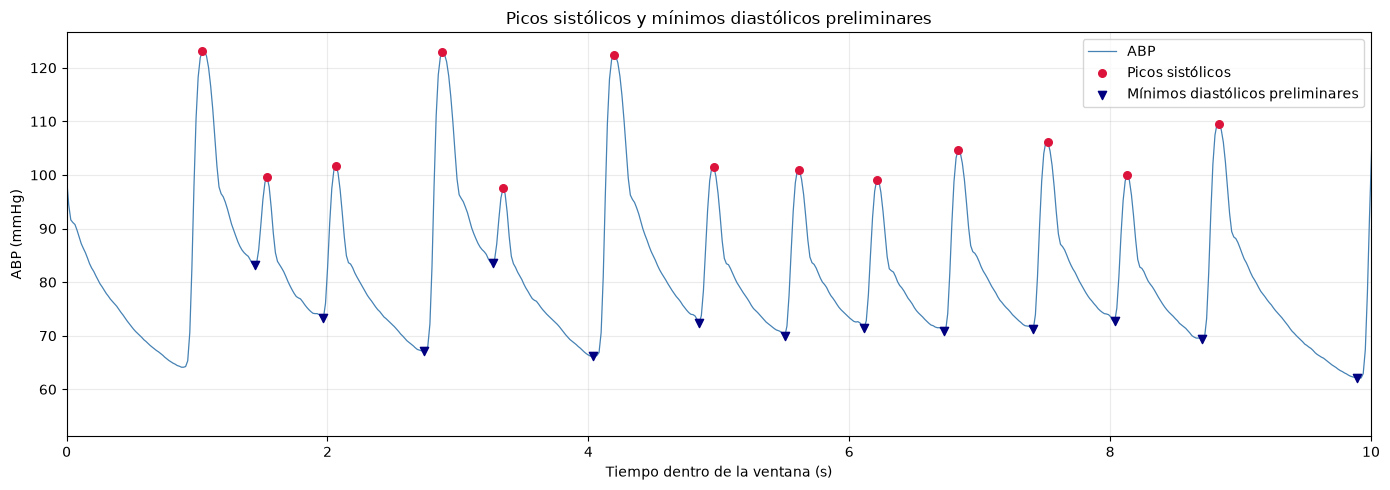

In [8]:
# Caracterización preliminar de cada intervalo entre picos sistólicos.
# Todavía no se estima la constante de tiempo diastólica.

beat_rows = []

for beat_number in range(len(systolic_peaks) - 1):
    start_peak = systolic_peaks[beat_number]
    end_peak = systolic_peaks[beat_number + 1]

    beat_signal = signal[start_peak:end_peak]
    beat_duration = (end_peak - start_peak) / best_fs

    if len(beat_signal) < 3:
        continue

    # El mínimo previo al siguiente pico se usa como presión diastólica
    # preliminar. Después refinaremos la separación sistólica/diastólica.
    relative_minimum = int(np.argmin(beat_signal))
    diastolic_index = start_peak + relative_minimum

    systolic_pressure = float(signal[start_peak])
    diastolic_pressure = float(signal[diastolic_index])
    pulse_pressure = systolic_pressure - diastolic_pressure
    heart_rate = 60.0 / beat_duration

    plausible = (
        0.35 <= beat_duration <= 1.50
        and 40 <= systolic_pressure <= 250
        and 20 <= diastolic_pressure <= 160
        and 10 <= pulse_pressure <= 120
        and systolic_pressure > diastolic_pressure
    )

    beat_rows.append(
        {
            "beat": beat_number + 1,
            "start_peak": start_peak,
            "diastolic_index": diastolic_index,
            "duration_s": beat_duration,
            "heart_rate_bpm": heart_rate,
            "systolic_mmhg": systolic_pressure,
            "diastolic_mmhg": diastolic_pressure,
            "pulse_pressure_mmhg": pulse_pressure,
            "plausible": plausible,
        }
    )

beat_table = pd.DataFrame(beat_rows)

print("Intervalos entre pulsos analizados:", len(beat_table))
print("Pulsos plausibles preliminares:", int(beat_table["plausible"].sum()))
print(
    "Pulsos excluidos preliminarmente:",
    int((~beat_table["plausible"]).sum()),
)

display(
    beat_table[
        [
            "beat",
            "duration_s",
            "heart_rate_bpm",
            "systolic_mmhg",
            "diastolic_mmhg",
            "pulse_pressure_mmhg",
            "plausible",
        ]
    ].round(2)
)

if len(beat_table) > 0:
    print("\nResumen de pulsos")
    print("-----------------")
    print(
        "Duración mediana:",
        round(float(beat_table["duration_s"].median()), 3),
        "s",
    )
    print(
        "Sistólica mediana:",
        round(float(beat_table["systolic_mmhg"].median()), 2),
        "mmHg",
    )
    print(
        "Diastólica mediana:",
        round(float(beat_table["diastolic_mmhg"].median()), 2),
        "mmHg",
    )
    print(
        "Presión de pulso mediana:",
        round(float(beat_table["pulse_pressure_mmhg"].median()), 2),
        "mmHg",
    )

plausible_beats = beat_table[beat_table["plausible"]]

plt.figure(figsize=(14, 5))
plt.plot(
    time,
    signal,
    color="steelblue",
    linewidth=0.9,
    label="ABP",
)

plt.scatter(
    time[systolic_peaks],
    signal[systolic_peaks],
    color="crimson",
    s=30,
    zorder=3,
    label="Picos sistólicos",
)

if len(plausible_beats) > 0:
    diastolic_indices = plausible_beats[
        "diastolic_index"
    ].astype(int).to_numpy()

    plt.scatter(
        time[diastolic_indices],
        signal[diastolic_indices],
        color="navy",
        marker="v",
        s=35,
        zorder=3,
        label="Mínimos diastólicos preliminares",
    )

plt.xlabel("Tiempo dentro de la ventana (s)")
plt.ylabel("ABP (mmHg)")
plt.title("Picos sistólicos y mínimos diastólicos preliminares")
plt.xlim(0, 10)
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

In [9]:
from scipy.optimize import least_squares

# Estimación exploratoria de la constante de tiempo diastólica efectiva.
# Modelo: P(t) = Pv + (P0 - Pv) * exp(-t / tau)
# Pv = 5 mmHg es un supuesto y deberá evaluarse mediante sensibilidad.

venous_pressure_assumed = 5.0
tau_rows = []
fitted_examples = []

for row in plausible_beats.itertuples(index=False):
    peak_index = int(row.start_peak)
    minimum_index = int(row.diastolic_index)

    beat_length = minimum_index - peak_index

    if beat_length < 8:
        continue

    # Se excluye la parte inicial posterior al pico para reducir
    # la influencia de la eyección y de la incisura dicrótica.
    fit_start = peak_index + max(
        2,
        int(round(0.35 * beat_length)),
    )
    fit_stop = minimum_index + 1

    pressure_decay = signal[fit_start:fit_stop]
    time_decay = (
        np.arange(len(pressure_decay), dtype=float) / best_fs
    )

    finite = (
        np.isfinite(pressure_decay)
        & (pressure_decay > venous_pressure_assumed)
    )

    pressure_decay = pressure_decay[finite]
    time_decay = time_decay[finite]

    if len(pressure_decay) < 8:
        continue

    initial_decay_pressure = float(pressure_decay[0])

    def residual(log_tau):
        tau = float(np.exp(log_tau[0]))

        predicted = (
            venous_pressure_assumed
            + (
                initial_decay_pressure
                - venous_pressure_assumed
            )
            * np.exp(-time_decay / tau)
        )

        return predicted - pressure_decay

    result = least_squares(
        residual,
        x0=np.log([1.5]),
        bounds=(
            np.log([0.10]),
            np.log([10.0]),
        ),
    )

    tau = float(np.exp(result.x[0]))

    predicted = (
        venous_pressure_assumed
        + (
            initial_decay_pressure
            - venous_pressure_assumed
        )
        * np.exp(-time_decay / tau)
    )

    residual_sum_squares = float(
        np.sum((pressure_decay - predicted) ** 2)
    )

    total_sum_squares = float(
        np.sum(
            (
                pressure_decay
                - np.mean(pressure_decay)
            ) ** 2
        )
    )

    r_squared = (
        1.0 - residual_sum_squares / total_sum_squares
        if total_sum_squares > 0
        else np.nan
    )

    rmse = float(
        np.sqrt(
            np.mean(
                (pressure_decay - predicted) ** 2
            )
        )
    )

    acceptable_fit = (
        result.success
        and 0.20 <= tau <= 5.00
        and r_squared >= 0.90
        and rmse <= 2.5
    )

    tau_rows.append(
        {
            "beat": int(row.beat),
            "tau_seconds": tau,
            "r_squared": r_squared,
            "rmse_mmhg": rmse,
            "samples_used": len(pressure_decay),
            "acceptable_fit": acceptable_fit,
        }
    )

    if acceptable_fit and len(fitted_examples) < 4:
        fitted_examples.append(
            {
                "beat": int(row.beat),
                "time": time_decay,
                "observed": pressure_decay,
                "predicted": predicted,
                "tau": tau,
                "r_squared": r_squared,
            }
        )

tau_table = pd.DataFrame(tau_rows)

print("Latidos evaluados para tau:", len(tau_table))

if tau_table.empty:
    print("No fue posible evaluar latidos.")
else:
    accepted_tau = tau_table[
        tau_table["acceptable_fit"]
    ]

    print(
        "Ajustes aceptables:",
        len(accepted_tau),
    )
    print(
        "Ajustes rechazados:",
        len(tau_table) - len(accepted_tau),
    )

    display(tau_table.round(3))

    if not accepted_tau.empty:
        print("\nResumen exploratorio de tau")
        print("---------------------------")
        print(
            "Tau mediana:",
            round(
                float(
                    accepted_tau["tau_seconds"].median()
                ),
                3,
            ),
            "s",
        )
        print(
            "Rango intercuartílico:",
            round(
                float(
                    accepted_tau["tau_seconds"].quantile(0.25)
                ),
                3,
            ),
            "-",
            round(
                float(
                    accepted_tau["tau_seconds"].quantile(0.75)
                ),
                3,
            ),
            "s",
        )
        print(
            "R² mediano:",
            round(
                float(
                    accepted_tau["r_squared"].median()
                ),
                3,
            ),
        )

if fitted_examples:
    figure, axes = plt.subplots(
        len(fitted_examples),
        1,
        figsize=(10, 3 * len(fitted_examples)),
        squeeze=False,
    )

    for axis, example in zip(
        axes.ravel(),
        fitted_examples,
    ):
        axis.plot(
            example["time"],
            example["observed"],
            marker="o",
            markersize=3,
            linewidth=1,
            label="ABP observada",
        )

        axis.plot(
            example["time"],
            example["predicted"],
            linewidth=2,
            label="Caída exponencial ajustada",
        )

        axis.set_title(
            f"Latido {example['beat']}: "
            f"tau={example['tau']:.3f} s, "
            f"R²={example['r_squared']:.3f}"
        )
        axis.set_xlabel("Tiempo desde el inicio del ajuste (s)")
        axis.set_ylabel("ABP (mmHg)")
        axis.grid(alpha=0.25)
        axis.legend()

    plt.tight_layout()
    plt.show()
else:
    print(
        "Ningún ajuste cumplió todos los criterios preliminares."
    )

Latidos evaluados para tau: 39
Ajustes aceptables: 34
Ajustes rechazados: 5


,beat,tau_seconds,r_squared,rmse_mmhg,samples_used,acceptable_fit
0,1,1.448,0.967,0.797,17,True
1,2,2.301,0.897,0.733,19,False
2,3,2.524,0.989,0.334,28,True
3,4,1.544,0.980,0.606,17,True
4,5,2.654,0.997,0.190,29,True
5,6,1.691,0.960,1.013,28,True
6,7,2.374,0.964,0.533,23,True
7,8,2.389,0.950,0.581,21,True
8,9,2.423,0.945,0.622,22,True
9,10,2.217,0.944,0.734,24,True



Resumen exploratorio de tau
---------------------------
Tau mediana: 2.431 s
Rango intercuartílico: 2.179 - 2.653 s
R² mediano: 0.967


,venous_pressure_mmhg,fit_start_fraction,accepted_beats,tau_median_s,tau_q25_s,tau_q75_s,r2_median,rmse_median_mmhg
0,0.0,0.25,35,2.401,2.183,2.533,0.948,0.768
1,0.0,0.35,34,2.605,2.335,2.843,0.966,0.586
2,0.0,0.45,36,2.884,2.651,3.085,0.969,0.398
3,0.0,0.55,35,3.142,2.845,3.389,0.974,0.314
4,5.0,0.25,35,2.237,2.040,2.364,0.950,0.761
5,5.0,0.35,34,2.431,2.179,2.653,0.967,0.581
6,5.0,0.45,36,2.682,2.470,2.865,0.969,0.395
7,5.0,0.55,35,2.931,2.645,3.153,0.975,0.311
8,10.0,0.25,35,2.072,1.897,2.194,0.952,0.753
9,10.0,0.35,35,2.250,2.012,2.459,0.967,0.576



Tau mediana según los supuestos


venous_pressure_mmhg,0.0,5.0,10.0,15.0
fit_start_fraction,,,,
0.25,2.401,2.237,2.072,1.908
0.35,2.605,2.431,2.250,2.066
0.45,2.884,2.682,2.480,2.280
0.55,3.142,2.931,2.714,2.502



Número de latidos aceptados


venous_pressure_mmhg,0.0,5.0,10.0,15.0
fit_start_fraction,,,,
0.25,35,35,35,36
0.35,34,34,35,36
0.45,36,36,36,36
0.55,35,35,36,36


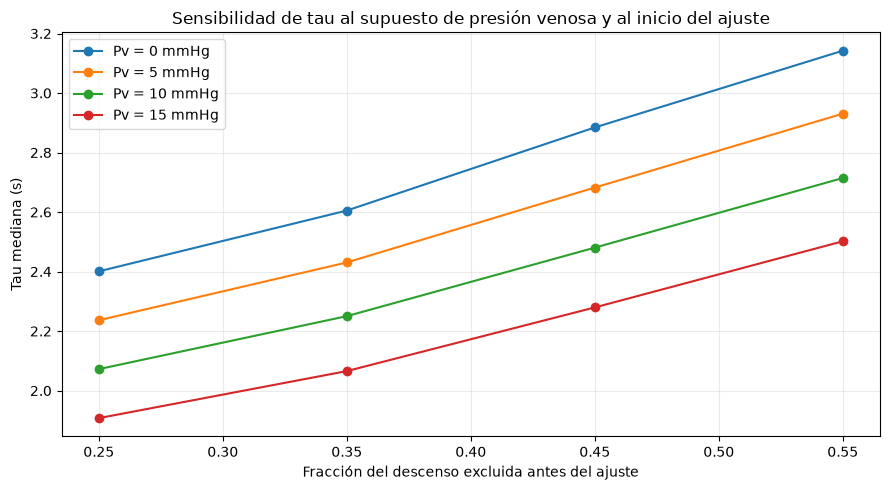

Resumen global de sensibilidad
--------------------------------
Tau mediana mínima entre configuraciones: 1.908 s
Tau mediana máxima entre configuraciones: 3.142 s
Variación absoluta: 1.235 s


In [10]:
# Análisis de sensibilidad de tau respecto a:
# 1. presión venosa asumida;
# 2. inicio del tramo diastólico ajustado.
#
# Este análisis no modifica la señal ni estima R y C por separado.

venous_pressure_values = [0.0, 5.0, 10.0, 15.0]
fit_start_fractions = [0.25, 0.35, 0.45, 0.55]

sensitivity_rows = []

for venous_pressure in venous_pressure_values:
    for fit_fraction in fit_start_fractions:
        combination_tau = []
        combination_r2 = []
        combination_rmse = []

        for row in plausible_beats.itertuples(index=False):
            peak_index = int(row.start_peak)
            minimum_index = int(row.diastolic_index)
            beat_length = minimum_index - peak_index

            if beat_length < 8:
                continue

            fit_start = peak_index + max(
                2,
                int(round(fit_fraction * beat_length)),
            )
            fit_stop = minimum_index + 1

            pressure_decay = np.asarray(
                signal[fit_start:fit_stop],
                dtype=float,
            )

            time_decay = (
                np.arange(len(pressure_decay), dtype=float)
                / best_fs
            )

            finite = (
                np.isfinite(pressure_decay)
                & (pressure_decay > venous_pressure)
            )

            pressure_decay = pressure_decay[finite]
            time_decay = time_decay[finite]

            if len(pressure_decay) < 8:
                continue

            initial_pressure = float(pressure_decay[0])

            def sensitivity_residual(log_tau):
                tau = float(np.exp(log_tau[0]))

                predicted = (
                    venous_pressure
                    + (initial_pressure - venous_pressure)
                    * np.exp(-time_decay / tau)
                )

                return predicted - pressure_decay

            result = least_squares(
                sensitivity_residual,
                x0=np.log([2.0]),
                bounds=(
                    np.log([0.10]),
                    np.log([10.0]),
                ),
            )

            tau = float(np.exp(result.x[0]))

            predicted = (
                venous_pressure
                + (initial_pressure - venous_pressure)
                * np.exp(-time_decay / tau)
            )

            residuals = pressure_decay - predicted
            rss = float(np.sum(residuals ** 2))
            tss = float(
                np.sum(
                    (
                        pressure_decay
                        - np.mean(pressure_decay)
                    ) ** 2
                )
            )

            r_squared = (
                1.0 - rss / tss
                if tss > 0
                else np.nan
            )

            rmse = float(
                np.sqrt(np.mean(residuals ** 2))
            )

            acceptable = (
                result.success
                and 0.20 <= tau <= 5.00
                and r_squared >= 0.90
                and rmse <= 2.5
            )

            if acceptable:
                combination_tau.append(tau)
                combination_r2.append(r_squared)
                combination_rmse.append(rmse)

        if combination_tau:
            sensitivity_rows.append(
                {
                    "venous_pressure_mmhg":
                        venous_pressure,
                    "fit_start_fraction":
                        fit_fraction,
                    "accepted_beats":
                        len(combination_tau),
                    "tau_median_s":
                        np.median(combination_tau),
                    "tau_q25_s":
                        np.percentile(combination_tau, 25),
                    "tau_q75_s":
                        np.percentile(combination_tau, 75),
                    "r2_median":
                        np.median(combination_r2),
                    "rmse_median_mmhg":
                        np.median(combination_rmse),
                }
            )

sensitivity_table = pd.DataFrame(sensitivity_rows)

display(
    sensitivity_table.round(
        {
            "fit_start_fraction": 2,
            "tau_median_s": 3,
            "tau_q25_s": 3,
            "tau_q75_s": 3,
            "r2_median": 3,
            "rmse_median_mmhg": 3,
        }
    )
)

tau_pivot = sensitivity_table.pivot(
    index="fit_start_fraction",
    columns="venous_pressure_mmhg",
    values="tau_median_s",
)

accepted_pivot = sensitivity_table.pivot(
    index="fit_start_fraction",
    columns="venous_pressure_mmhg",
    values="accepted_beats",
)

print("\nTau mediana según los supuestos")
display(tau_pivot.round(3))

print("\nNúmero de latidos aceptados")
display(accepted_pivot)

plt.figure(figsize=(9, 5))

for venous_pressure in venous_pressure_values:
    subset = sensitivity_table[
        sensitivity_table["venous_pressure_mmhg"]
        == venous_pressure
    ]

    plt.plot(
        subset["fit_start_fraction"],
        subset["tau_median_s"],
        marker="o",
        linewidth=1.5,
        label=f"Pv = {venous_pressure:.0f} mmHg",
    )

plt.xlabel("Fracción del descenso excluida antes del ajuste")
plt.ylabel("Tau mediana (s)")
plt.title(
    "Sensibilidad de tau al supuesto de presión venosa "
    "y al inicio del ajuste"
)
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

print("Resumen global de sensibilidad")
print("--------------------------------")
print(
    "Tau mediana mínima entre configuraciones:",
    round(float(sensitivity_table["tau_median_s"].min()), 3),
    "s",
)
print(
    "Tau mediana máxima entre configuraciones:",
    round(float(sensitivity_table["tau_median_s"].max()), 3),
    "s",
)
print(
    "Variación absoluta:",
    round(
        float(
            sensitivity_table["tau_median_s"].max()
            - sensitivity_table["tau_median_s"].min()
        ),
        3,
    ),
    "s",
)

In [11]:
from IPython.display import display, Markdown

conclusion = """
## Conclusión preliminar del análisis de sensibilidad

La estimación de la constante de tiempo diastólica efectiva fue sensible tanto a la presión venosa asumida como al inicio del tramo utilizado para el ajuste.

En la ventana exploratoria se evaluaron 39 latidos. Entre 34 y 36 latidos cumplieron los criterios de aceptación, dependiendo de la configuración. La mediana de tau varió entre 1.908 y 3.142 s, con una variación absoluta de 1.235 s.

El número relativamente estable de ajustes aceptados indica que el modelo exponencial puede representar adecuadamente numerosos descensos diastólicos. Sin embargo, la variación de tau entre configuraciones demuestra que su valor absoluto depende de supuestos metodológicos.

Por tanto:

1. tau se interpretará como una constante de tiempo diastólica efectiva del modelo;
2. no se utilizará para identificar R y C por separado;
3. no se considerará una medición fisiológica directa;
4. se preespecificará un procedimiento uniforme para todas las ventanas;
5. se reportará análisis de sensibilidad a la presión venosa asumida y al inicio del ajuste;
6. los resultados de esta única ventana se consideran exploratorios y no representan la cohorte.
"""

display(Markdown(conclusion))


## Conclusión preliminar del análisis de sensibilidad

La estimación de la constante de tiempo diastólica efectiva fue sensible tanto a la presión venosa asumida como al inicio del tramo utilizado para el ajuste.

En la ventana exploratoria se evaluaron 39 latidos. Entre 34 y 36 latidos cumplieron los criterios de aceptación, dependiendo de la configuración. La mediana de tau varió entre 1.908 y 3.142 s, con una variación absoluta de 1.235 s.

El número relativamente estable de ajustes aceptados indica que el modelo exponencial puede representar adecuadamente numerosos descensos diastólicos. Sin embargo, la variación de tau entre configuraciones demuestra que su valor absoluto depende de supuestos metodológicos.

Por tanto:

1. tau se interpretará como una constante de tiempo diastólica efectiva del modelo;
2. no se utilizará para identificar R y C por separado;
3. no se considerará una medición fisiológica directa;
4. se preespecificará un procedimiento uniforme para todas las ventanas;
5. se reportará análisis de sensibilidad a la presión venosa asumida y al inicio del ajuste;
6. los resultados de esta única ventana se consideran exploratorios y no representan la cohorte.


In [12]:
# Guardado local de resultados exploratorios.
# La carpeta outputs está excluida de Git.

exploratory_output = PROJECT_ROOT / "outputs" / "exploratory_abp"
exploratory_output.mkdir(parents=True, exist_ok=True)

beat_table.to_csv(
    exploratory_output / "beat_characterization.csv",
    index=False,
)

tau_table.to_csv(
    exploratory_output / "tau_per_beat.csv",
    index=False,
)

sensitivity_table.to_csv(
    exploratory_output / "tau_sensitivity.csv",
    index=False,
)

print("Resultados guardados localmente.")
print("Archivos creados:")

for output_file in sorted(exploratory_output.glob("*.csv")):
    print("-", output_file.name)

Resultados guardados localmente.
Archivos creados:
- beat_characterization.csv
- tau_per_beat.csv
- tau_sensitivity.csv
